# Figure 1 - Analysis/Figure Code

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
DATA_PATH = "../../cnt-data/"

In [3]:
# This is the example patient's HUP ID
patient_hup_id = 142

# Load in the patient's "giant table"
hourly_patient_features_df = pd.read_csv(
    os.path.join(DATA_PATH, f"giant_new_tables/HUP_{str(patient_hup_id)}.csv")
)

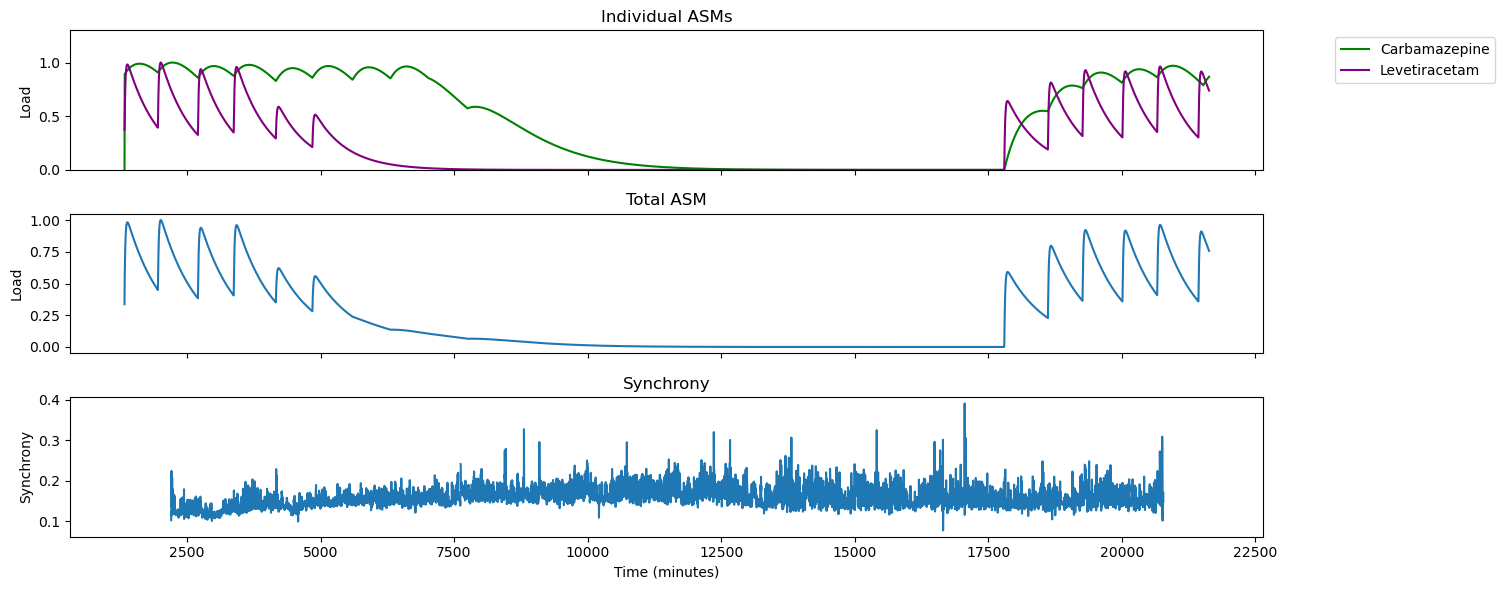

In [ ]:
med_cols = [
    col
    for col in hourly_patient_features_df.columns
    if col.startswith("med_") and not hourly_patient_features_df[col].eq(0).all()
]
med_cols_no_raw = [col.split("_raw")[0] for col in med_cols]

fig, ax = plt.subplots(3, 1, figsize=(15, 6), sharex=True)

# Define a color cycle excluding blue and red
color_cycle = ["green", "purple", "orange", "brown", "pink", "cyan", "gray", "black"]
num_colors = len(color_cycle)

# Plotting Individual ASMs
for i, col in enumerate(med_cols):
    if "med_sum_no_lorazepam" not in col:
        label = med_cols_no_raw[i].replace("med_", "").capitalize()
        normalized_data = (
            hourly_patient_features_df[col] / hourly_patient_features_df[col].max()
        )
        ax[0].plot(
            hourly_patient_features_df["emu_minute"],
            normalized_data,
            label=label,
            color=color_cycle[i % num_colors],  # Cycle through non-blue/red colors
        )

ax[0].set_ylabel("Load")
ax[0].set_ylim([0, 1.3])
ax[0].legend(loc="upper right", bbox_to_anchor=(1.2, 1))  # Adding the legend
ax[0].set_title("Individual ASMs")

ax[1].plot(
    hourly_patient_features_df["emu_minute"],
    hourly_patient_features_df["med_sum_no_lorazepam_raw"],
)
ax[1].set_ylabel("Load")
ax[1].set_title("Total ASM")

# Plotting synchrony (broadband Band)
ax[2].plot(
    hourly_patient_features_df["emu_minute"],
    hourly_patient_features_df["synchrony_broadband"],
)
ax[2].set_ylabel("Synchrony")
ax[2].set_title("Synchrony")

ax[2].set_xlabel("Time (minutes)")
plt.tight_layout()
plt.show()